# TTP and Clinical Failure Outcomes

Persistent bacteremia / microbiological clearance / relapse (v4 update)

In [ ]:
#| include: false
suppressPackageStartupMessages({
  library(tidyverse); library(brms); library(metafor)
  library(posterior); library(ggdist); library(gt); library(patchwork)
})

Pool: 100 studies (inclusive_pool=FALSE, drop_contaminated=TRUE)

# Pre-analysis feasibility check

In the v1 analysis (n=57 studies, Feb 2026), the clinical failure analysis was deemed *not feasible*: only 4 studies had usable data, with severe directionality contradictions and one extreme outlier (OR≈1115 in Melling 2019). The v4 update adds 43 new strict-pool studies, several of which report persistent bacteremia, microbiological clearance, or relapse outcomes. This page revisits feasibility.

## Available data (strict pool, n=100 studies)

In [ ]:
#| label: tbl-counts
#| tbl-cap: "Available effect sizes per clinical-failure outcome (strict pool)."
counts |> gt() |>
  tab_style(style = cell_fill(color = "#FEF9C3"),
            locations = cells_body(rows = `Effect sizes` >= 5))

## Persistent bacteremia (most-reported clinical failure outcome)

Loading required namespace: rstan

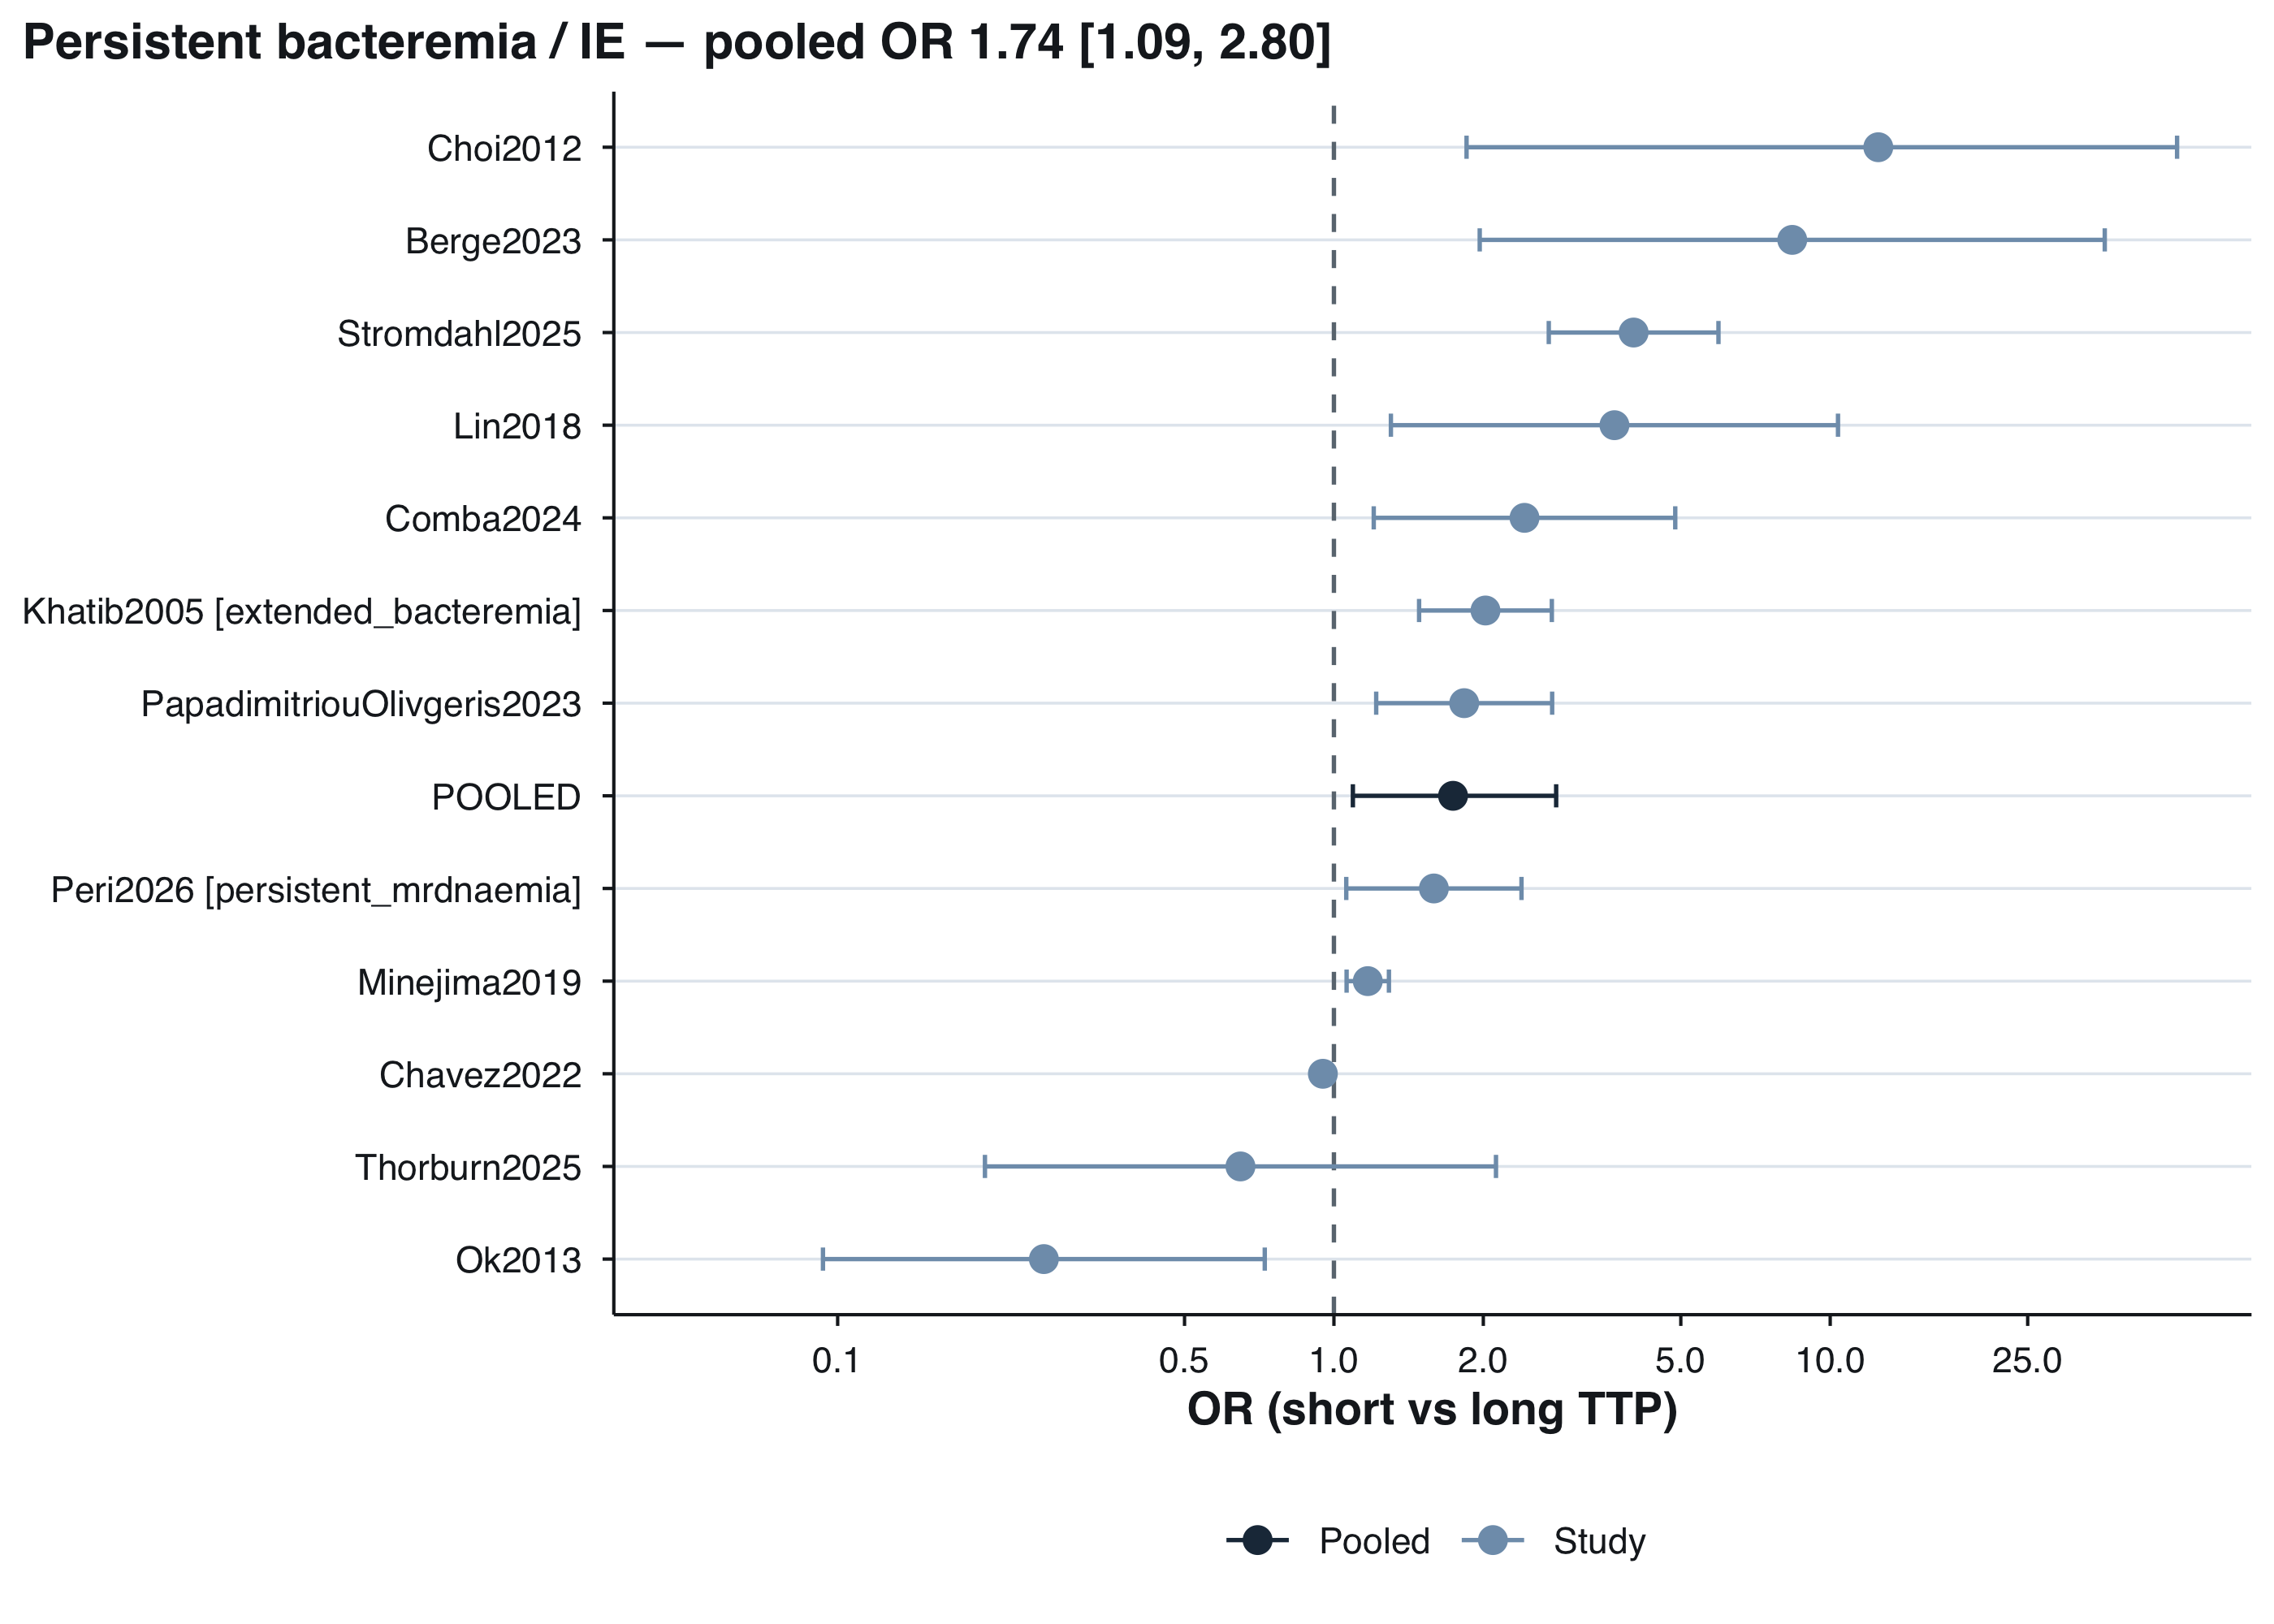

In [ ]:
#| label: fig-pb
#| fig-cap: "Forest plot of OR (short vs long TTP) for persistent bacteremia. NB: many studies coded under 'persistent_bacteremia' actually report endocarditis (the Codebook's outcome_type enum lacks 'endocarditis'). Review outcome_definition in each row before interpretation."

if (nrow(es_pb) >= 3) {
  fit_pb <- brm(
    bf(yi | se(sei) ~ 1 + (1 | study_id)),
    data = es_pb,
    prior = c(prior(normal(0, 1),   class = "Intercept"),
              prior(cauchy(0, 0.5), class = "sd")),
    chains = 4, iter = 4000, warmup = 1000, cores = 4, backend = "cmdstanr",
    control = list(adapt_delta = 0.99),
    file = "_brms_cache/primary/fit_pb", file_refit = "on_change",
    silent = 2, refresh = 0
  )
  pb_post <- pooled_summary(fit_pb)

  forest_pb <- es_pb |>
    mutate(or = exp(yi), ci_low = exp(yi - 1.96*sei), ci_high = exp(yi + 1.96*sei),
           lbl = paste0(study_id, ifelse(is.na(arm_id) | arm_id == "all", "", paste0(" [", arm_id, "]"))),
           type = "Study") |>
    bind_rows(tibble(lbl = "POOLED", or = pb_post$median_OR,
                     ci_low = pb_post$ci_OR[1], ci_high = pb_post$ci_OR[2], type = "Pooled"))

  ggplot(forest_pb, aes(x = or, y = reorder(lbl, or), color = type)) +
    geom_vline(xintercept = 1, linetype = "dashed", color = jama_ref_line) +
    geom_point(size = 2.5) +
    geom_errorbar(aes(xmin = pmax(ci_low, 0.05), xmax = pmin(ci_high, 50)),
                  width = 0.25, orientation = "y") +
    scale_color_manual(values = c("Study" = "#7F9DB9", "Pooled" = "#1F3447")) +
    scale_x_log10(breaks = c(0.1, 0.5, 1, 2, 5, 10, 25), limits = c(0.05, 50)) +
    labs(x = "OR (short vs long TTP)", y = NULL, color = NULL,
         title = sprintf("Persistent bacteremia / IE — pooled OR %.2f [%.2f, %.2f]",
                         pb_post$median_OR, pb_post$ci_OR[1], pb_post$ci_OR[2])) +
    theme_jama(base_size = 10) + theme(legend.position = "bottom")
} else {
  cat("Fewer than 3 effect sizes available — cannot fit pooled model.")
}

## Subset analysis: persistent bacteremia by outcome definition

The persistent bacteremia pool mixes genuinely different endpoints — true persistent/extended bacteremia, endocarditis/IE diagnoses, and other outcomes (e.g. line removal failure, mortality). We examine whether the definition group moderates the pooled effect.

Meta-regression: def_group moderator on persistent bacteremia

                         Estimate Est.Error   Q2.5 Q97.5
Intercept                   0.367     0.223 -0.052 0.857
def_groupendocarditis_IE    0.595     0.363 -0.192 1.242
def_groupother              0.259     0.373 -0.483 0.984

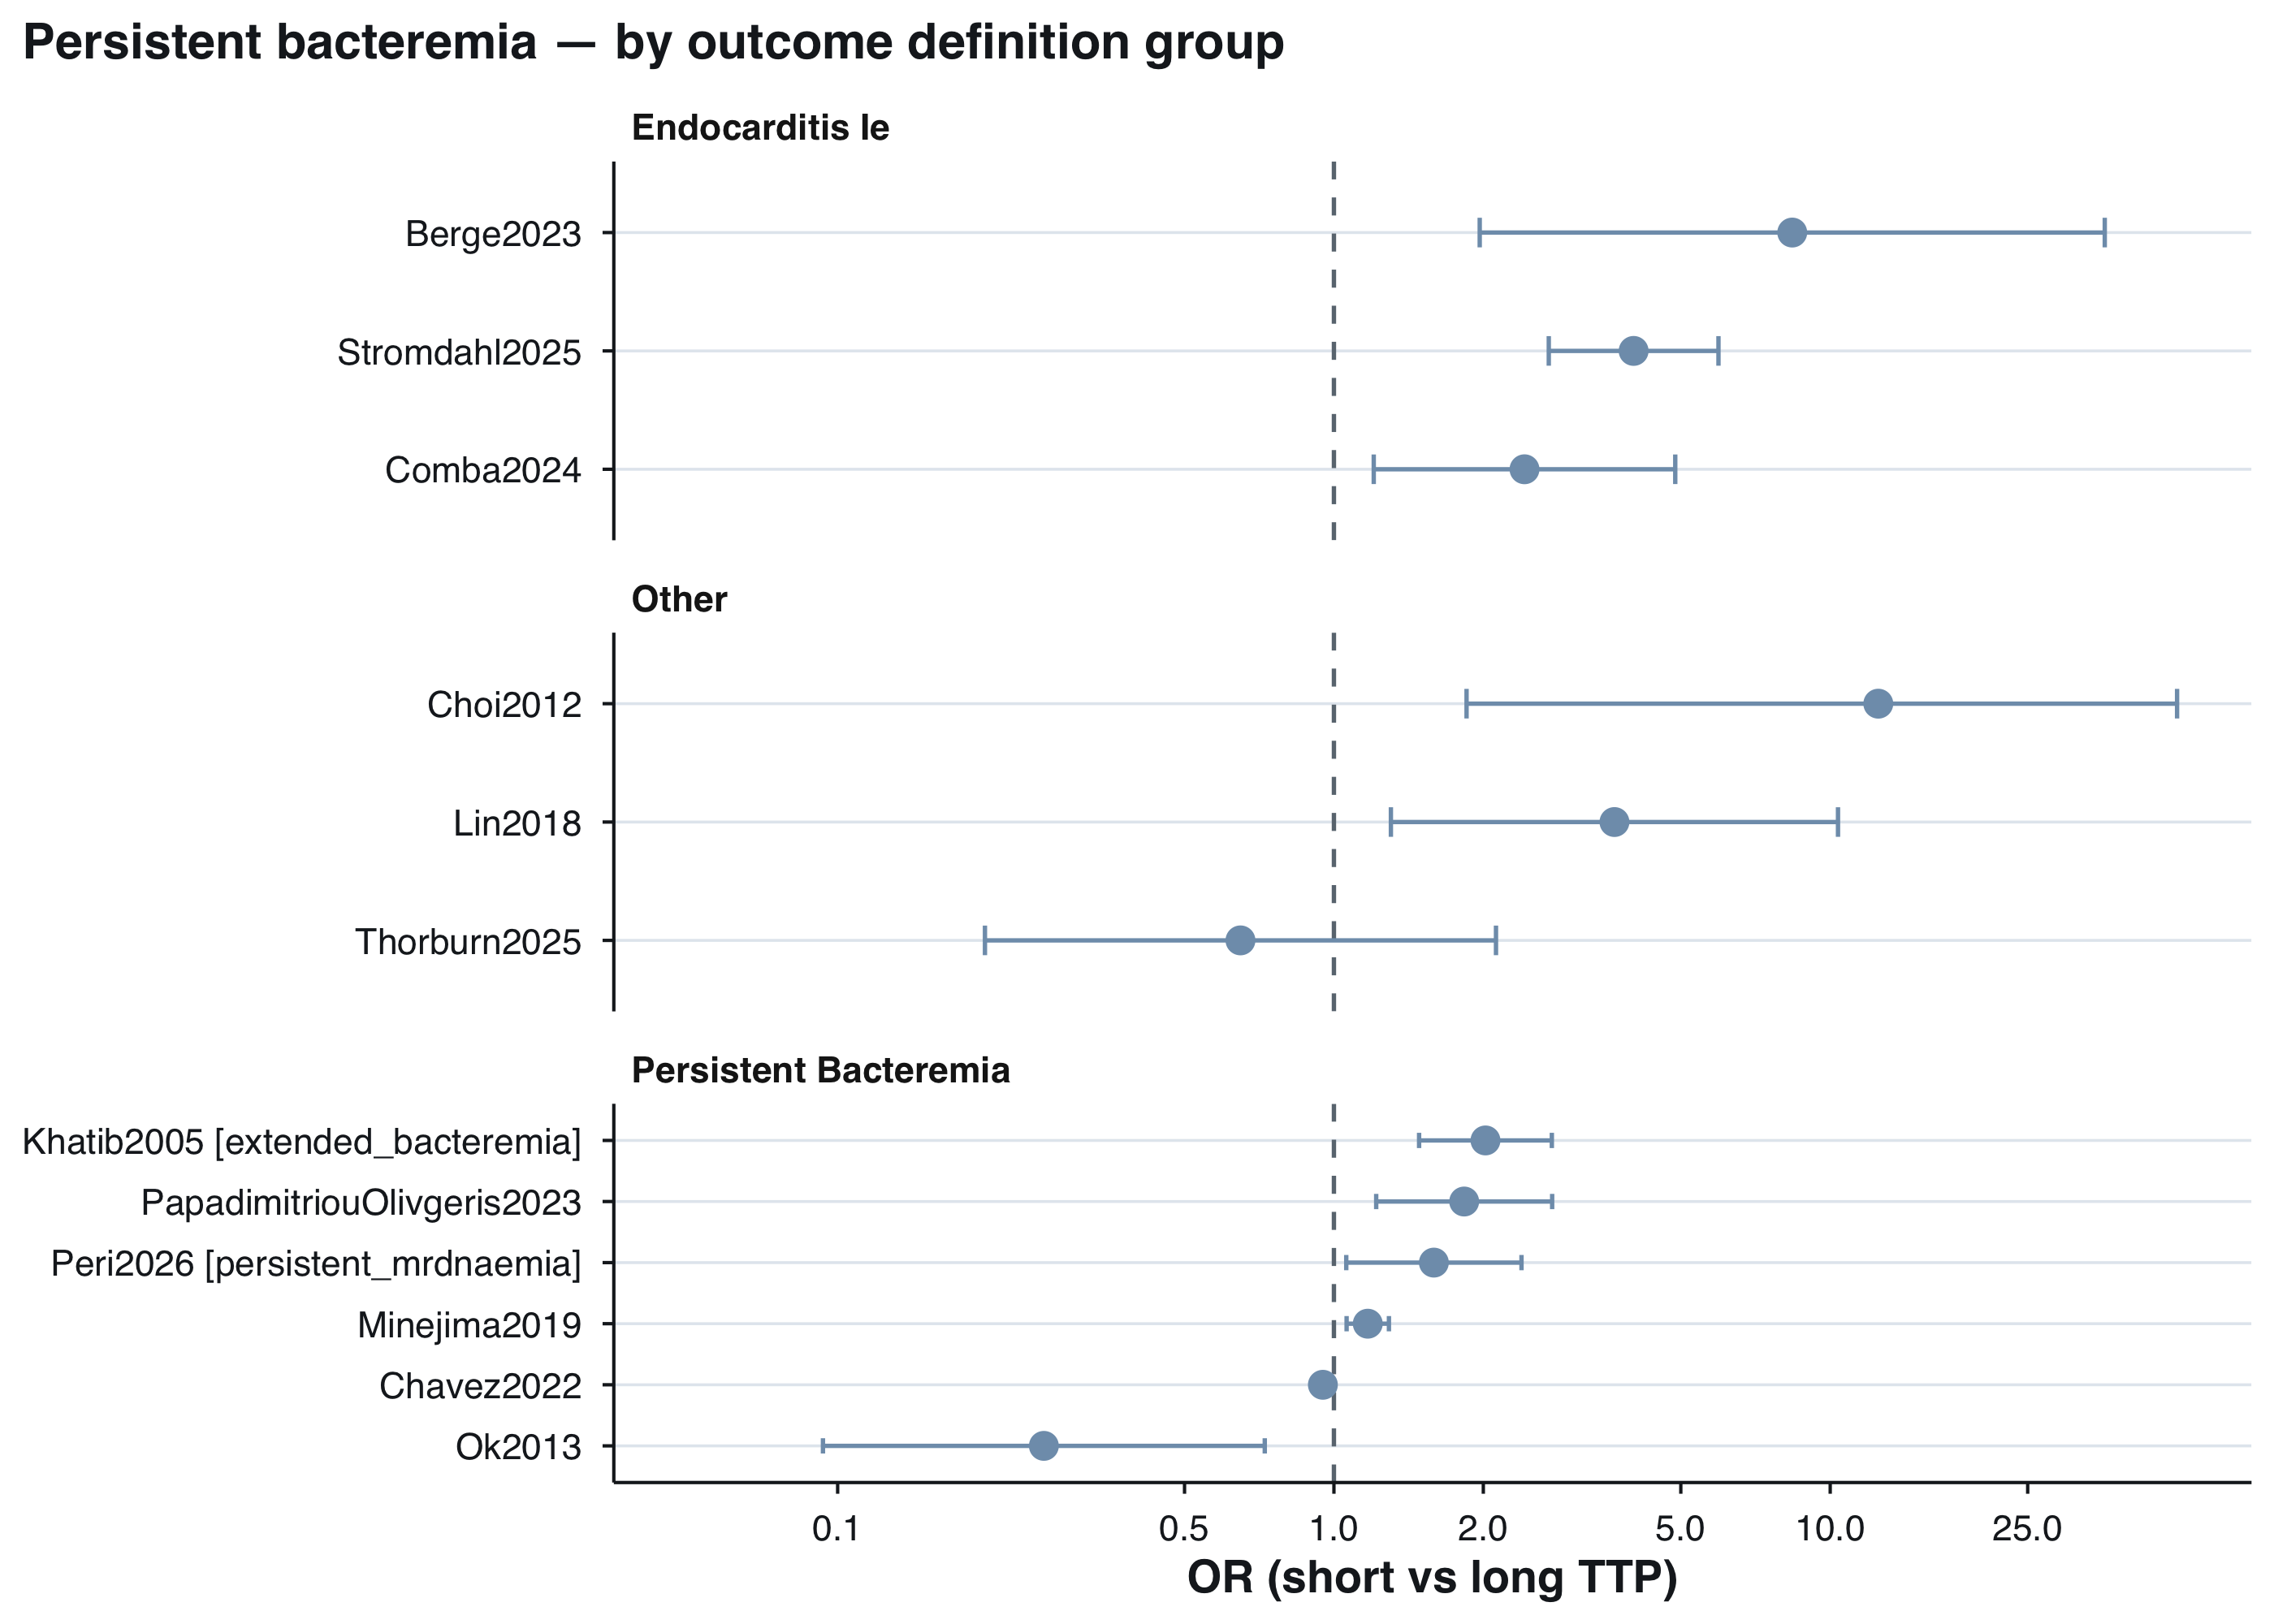

In [ ]:
#| fig-cap: "Forest plot of persistent bacteremia OR, faceted by outcome-definition group."
#| label: fig-pb-bydef

if (nrow(es_pb) >= 3 && n_distinct(es_pb$def_group) >= 2) {

  # -- Meta-regression with def_group moderator --
  es_pb_mr <- es_pb |>
    mutate(def_group = factor(def_group, levels = c("persistent_bacteremia",
                                                     "endocarditis_IE", "other")))
  fit_pb_def <- brm(
    bf(yi | se(sei) ~ 1 + def_group + (1 | study_id)),
    data = es_pb_mr,
    prior = c(prior(normal(0, 1),   class = "Intercept"),
              prior(cauchy(0, 0.5), class = "sd"),
              prior(normal(0, 0.5), class = "b")),
    chains = 4, iter = 4000, warmup = 1000, cores = 4, backend = "cmdstanr",
    control = list(adapt_delta = 0.99),
    file = "_brms_cache/primary/fit_pb_defgroup", file_refit = "on_change",
    silent = 2, refresh = 0
  )

  cat("Meta-regression: def_group moderator on persistent bacteremia\n\n")
  fixef(fit_pb_def) |> round(3) |> print()
  cat("\n")

  # -- Faceted forest plot --
  forest_bydef <- es_pb |>
    mutate(or = exp(yi), ci_low = exp(yi - 1.96*sei), ci_high = exp(yi + 1.96*sei),
           lbl = paste0(study_id, ifelse(is.na(arm_id) | arm_id == "all", "",
                                          paste0(" [", arm_id, "]"))),
           def_group_lbl = str_replace_all(def_group, "_", " ") |> str_to_title())

  ggplot(forest_bydef, aes(x = or, y = reorder(lbl, or))) +
    geom_vline(xintercept = 1, linetype = "dashed", color = jama_ref_line) +
    geom_point(size = 2.5, color = "#7F9DB9") +
    geom_errorbar(aes(xmin = pmax(ci_low, 0.05), xmax = pmin(ci_high, 50)),
                  width = 0.25, color = "#7F9DB9") +
    scale_x_log10(breaks = c(0.1, 0.5, 1, 2, 5, 10, 25), limits = c(0.05, 50)) +
    facet_wrap(~ def_group_lbl, scales = "free_y", ncol = 1) +
    labs(x = "OR (short vs long TTP)", y = NULL,
         title = "Persistent bacteremia — by outcome definition group") +
    theme_jama(base_size = 10)

} else {
  cat("Too few effect sizes or definition groups to fit subset model.")
}

> **Low-power caveat**
>
> The meta-regression has very few observations per group (≤6), so the moderator estimates are imprecise and should be treated as exploratory. The faceted forest plot is intended to highlight definitional heterogeneity, not to provide reliable subgroup-specific pooled effects.

## Microbiological clearance

In [ ]:
if (nrow(es_clr) >= 3) {
  fit_clr <- brm(
    bf(yi | se(sei) ~ 1 + (1 | study_id)),
    data = es_clr,
    prior = c(prior(normal(0, 1),   class = "Intercept"),
              prior(cauchy(0, 0.5), class = "sd")),
    chains = 4, iter = 4000, warmup = 1000, cores = 4, backend = "cmdstanr",
    control = list(adapt_delta = 0.99),
    file = "_brms_cache/primary/fit_clr", file_refit = "on_change",
    silent = 2, refresh = 0
  )
  clr_post <- pooled_summary(fit_clr)
  cat(sprintf("Microbiological clearance — pooled OR %.2f [%.2f, %.2f] from %d effect sizes (%d studies).\n",
              clr_post$median_OR, clr_post$ci_OR[1], clr_post$ci_OR[2],
              nrow(es_clr), n_distinct(es_clr$study_id)))
} else {
  cat(sprintf("Microbiological clearance: only %d effect sizes — insufficient for meta-analysis.\n", nrow(es_clr)))
}

Microbiological clearance — pooled OR 1.63 [0.24, 9.47] from 4 effect sizes (3 studies).

## Relapse

In [ ]:
if (nrow(es_rel) >= 3) {
  fit_rel <- brm(
    bf(yi | se(sei) ~ 1 + (1 | study_id)),
    data = es_rel,
    prior = c(prior(normal(0, 1),   class = "Intercept"),
              prior(cauchy(0, 0.5), class = "sd")),
    chains = 4, iter = 4000, warmup = 1000, cores = 4, backend = "cmdstanr",
    file = "_brms_cache/primary/fit_rel", file_refit = "on_change",
    silent = 2, refresh = 0
  )
  rel_post <- pooled_summary(fit_rel)
  cat(sprintf("Relapse — pooled OR %.2f [%.2f, %.2f] from %d effect sizes (%d studies).\n",
              rel_post$median_OR, rel_post$ci_OR[1], rel_post$ci_OR[2],
              nrow(es_rel), n_distinct(es_rel$study_id)))
} else {
  cat(sprintf("Relapse: only %d effect sizes — insufficient for meta-analysis.\n", nrow(es_rel)))
}

Relapse: only 0 effect sizes — insufficient for meta-analysis.

# Interpretation caveats carried forward from v1

> **Use with caution**
>
> 1.  **Outcome heterogeneity persists.** The Codebook’s `outcome_type` enum (`mortality | persistent_bacteremia | microbiological_clearance | relapse`) has been applied liberally for v4 — endocarditis, septic shock, IE-positive ECHO, and metastatic-infection outcomes are mapped to the nearest enum value with the actual outcome described in `outcome_definition`. Pool only after grouping rows whose `outcome_definition` is genuinely comparable.
>
> 2.  **Direction of association may flip across studies.** In v1, Ok2013 reported the *opposite* direction (short TTP → less persistent bacteremia) to the other studies — a real-world finding, not an extraction error. Look for similar directional outliers in v4.
>
> 3.  **Outcome definitions vary widely.** Persistent bacteremia at 48h, 72h, or 7 days; clearance defined as “first negative culture” vs “two consecutive negatives”; relapse within 30d vs 90d. These are *not* interchangeable. A subset analysis by definition group is included above (@fig-pb-bydef), but power is very low (≤6 effects per group).
>
> 4.  **Inclusive-pool studies (n=40) are excluded** from this page since their outcome data is largely descriptive (no TTP↔outcome model). If you want to add them, re-run with `include_inclusive_pool = TRUE` in the setup chunk.

# Outcome-definition table

In [ ]:
#| label: tbl-defs
#| tbl-cap: "Outcome definitions used by each contributing study (top 30 rows by study_id)."
bind_rows(
  es_pb  |> mutate(outcome_family = "persistent_bacteremia"),
  es_clr |> mutate(outcome_family = "microbiological_clearance", def_group = NA_character_),
  es_rel |> mutate(outcome_family = "relapse", def_group = NA_character_)
) |>
  select(study_id, arm_id, outcome_family, def_group,
         outcome_definition, outcome_timepoint_days) |>
  arrange(outcome_family, study_id) |>
  head(30) |> gt() |>
  tab_options(table.font.size = px(11))